**Question 3:**

In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import Dataset,DataLoader
import matplotlib.pyplot as plt

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

In [ ]:
train_dataset = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
test_dataset = datasets.MNIST(root='./data', train=False, transform=transform, download=True)

In [ ]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

In [ ]:
import random
random_index=random.randint(0,len(train_dataset)-1)
image,label=train_dataset[random_index]
print(image.shape)

torch.Size([1, 28, 28])


In [ ]:
import torch.nn as nn
class neural_net(nn.Module):
  def __init__(self):
    super(neural_net,self).__init__()
    self.fc1=nn.Linear(784,128)
    self.fc2=nn.Linear(128,64)
    self.fc3=nn.Linear(64,10)

  def forward(self,x):
    x=x.view(-1,784)
    x=self.fc1(x)
    x=torch.relu(x)
    x=torch.relu(self.fc2(x))
    x=self.fc3(x)
    return x
  def backward(self,loss):
    loss.backward()

import torch.optim as optim
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = neural_net().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

def train(epochs):
  for i in range(epochs):
    model.train()
    for idx,(data,target) in enumerate(train_loader):
      data,target=data.to(device),target.to(device)
      optimizer.zero_grad()
      output=model(data)
      loss=criterion(output,target)
      model.backward(loss)
      optimizer.step()
      if idx % 500 == 0:
        print(f"Epoch {i+1}/{epochs}, Batch {idx+1}/{len(train_loader)}, Loss: {loss.item()}")
  return model

def test_random_sample():
    model.eval()

    idx = random.randint(0, len(test_dataset) - 1)
    image, true_label = test_dataset[idx]

    plt.imshow(image.squeeze(), cmap='gray')
    plt.title(f"True Label: {true_label}")
    plt.axis('off')
    plt.show()

    image = image.unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(image)

    _, predicted_class = torch.max(output, 1)

    probabilities = torch.nn.functional.softmax(output, dim=1)

    print(f"Predicted Label: {predicted_class.item()}")
    print("Class Probabilities:")
    for i, prob in enumerate(probabilities[0]):
        print(f"Class {i}: {prob.item()*100:.2f}%")


In [ ]:
train(epochs=5)

Epoch 1/5, Batch 1/938, Loss: 2.299408197402954
Epoch 1/5, Batch 501/938, Loss: 0.09671914577484131
Epoch 2/5, Batch 1/938, Loss: 0.21627262234687805
Epoch 2/5, Batch 501/938, Loss: 0.1175546944141388
Epoch 3/5, Batch 1/938, Loss: 0.11789850145578384
Epoch 3/5, Batch 501/938, Loss: 0.0226764939725399
Epoch 4/5, Batch 1/938, Loss: 0.022747565060853958
Epoch 4/5, Batch 501/938, Loss: 0.021300004795193672
Epoch 5/5, Batch 1/938, Loss: 0.020878547802567482
Epoch 5/5, Batch 501/938, Loss: 0.045971985906362534


neural_net(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
)

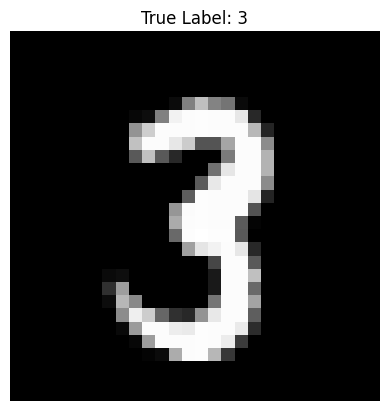

Predicted Label: 3
Class Probabilities:
Class 0: 0.00%
Class 1: 0.00%
Class 2: 0.00%
Class 3: 100.00%
Class 4: 0.00%
Class 5: 0.00%
Class 6: 0.00%
Class 7: 0.00%
Class 8: 0.00%
Class 9: 0.00%


In [ ]:
test_random_sample()

**Question 4:**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
x=np.arange(0,2*np.pi,0.1)
y=np.sin(x)

x_val=np.concatenate((np.linspace(-1*np.pi,0,1000),np.linspace(2*np.pi,3*np.pi,1000)))
y_val=np.sin(x_val)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
class SimpleNN(nn.Module):
  def __init__(self,activation_function):
    super(SimpleNN,self).__init__()
    self.activation=activation_function
    self.fc1=nn.Linear(1,64)
    self.fc2=nn.Linear(64,1)

  def forward(self,x):
    x=self.fc1(x)
    x=self.activation(x)
    x=self.fc2(x)
    return x

activation_functions={"ReLU":nn.ReLU(),"GeLU":nn.GELU(),"SiLU":nn.SiLU(),"LeakyReLU":nn.LeakyReLU(),"ELU":nn.ELU()}
networks = {name: SimpleNN(act_func) for name, act_func in activation_functions.items()}

def train(network,x_train,y_train,x_val,y_val,epochs=1000,lr=0.01):
  criterion=nn.MSELoss()
  optimizer=optim.Adam(network.parameters(),lr=lr)
  training_loss = []
  validation_loss = []

  for i in range(epochs):
    network.train()
    optimizer.zero_grad()
    output=network(x_train)
    loss=criterion(output,y_train)
    loss.backward()
    optimizer.step()
    training_loss.append(loss.item())
    network.eval()
    with torch.no_grad():
      output=network(x_val)
      val_loss=criterion(output,y_val)
      validation_loss.append(loss.item())

  return training_loss,validation_loss

In [ ]:
results={}
x_train=torch.Tensor(x).unsqueeze(1)
y_train=torch.Tensor(y).unsqueeze(1)
x_val=torch.Tensor(x_val).unsqueeze(1)
y_val=torch.Tensor(y_val).unsqueeze(1)
for name,network in networks.items():
  training_loss,validation_loss=train(network,x_train,y_train,x_val,y_val,epochs=1000,lr=0.01)
  results[name]={"Network":network,"train_loss":training_loss,"val_loss":validation_loss}

sorted_results = sorted(results.items(), key=lambda x: min(x[1]['val_loss']))

print("Order of activation functions by minimum validation loss:")
for name, result in sorted_results:
    print(f"{name}: {min(result['val_loss'])}")

Order of activation functions by minimum validation loss:
GeLU: 1.1101047675765585e-05
SiLU: 4.428025567904115e-05
LeakyReLU: 0.0001383751950925216
ELU: 0.0001823971833800897
ReLU: 0.00030360042001120746


<ipython-input-19-524027d7eb5b>:19: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  axs[i].plot(x_plot, y_true, 'k--', label='True function',color='yellow')


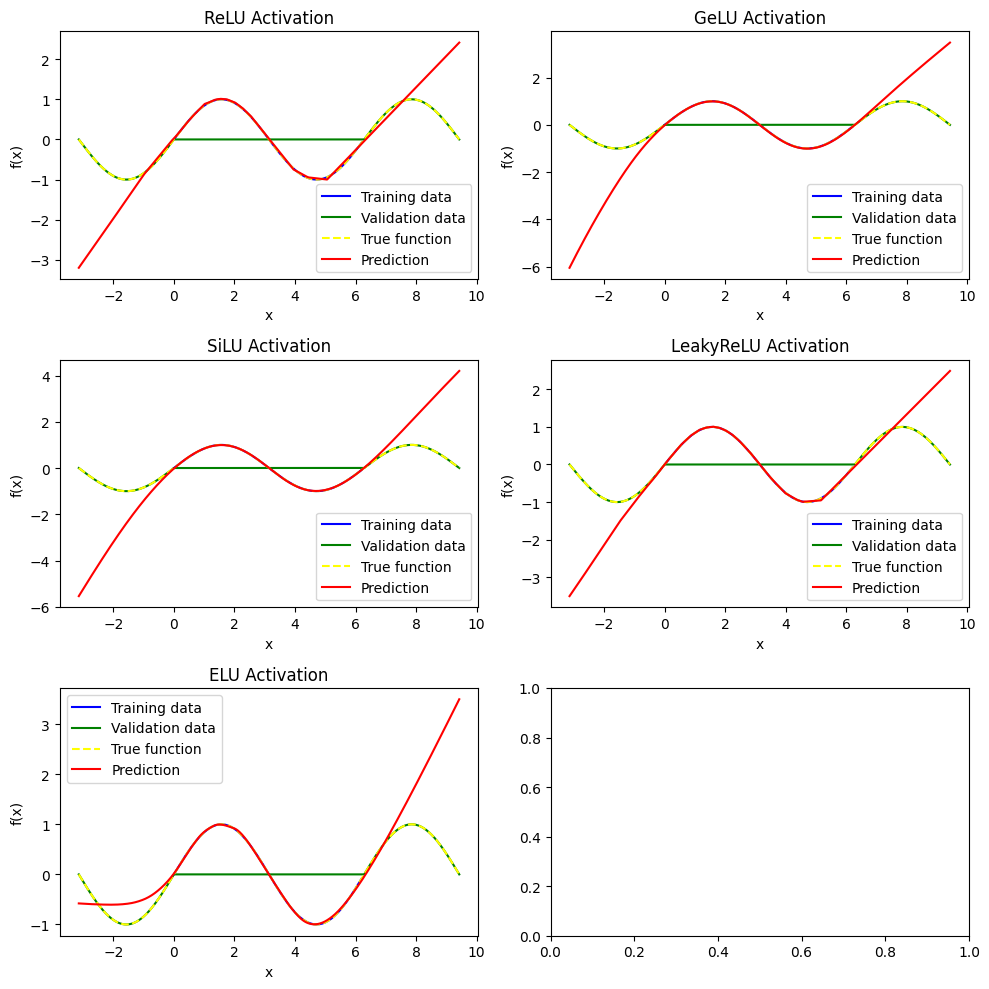

In [ ]:
fig, axs = plt.subplots(3, 2, figsize=(10, 10))
axs = axs.ravel()

x_plot = np.linspace(-np.pi, 3 * np.pi, 1000)
y_true = np.sin(x_plot)

x_train=x_train.reshape(-1)
y_train=y_train.reshape(-1)
x_val=x_val.reshape(-1)
y_val=y_val.reshape(-1)
for i, (name, result) in enumerate(results.items()):
    network = result['Network']

    with torch.no_grad():
        y_pred = network(torch.Tensor(x_plot).unsqueeze(1)).numpy().flatten()

    axs[i].plot(x_train, y_train, 'b', label='Training data')
    axs[i].plot(x_val, y_val, 'g', label='Validation data')
    axs[i].plot(x_plot, y_true, 'k--', label='True function',color='yellow')
    axs[i].plot(x_plot, y_pred, 'r', label='Prediction')
    axs[i].set_title(f'{name} Activation')
    axs[i].legend()
    axs[i].set_xlabel('x')
    axs[i].set_ylabel('f(x)')

plt.tight_layout()
plt.show()

smoother activation functions like GELU or SiLU can perform better in approximating continuous functions like sine due to their non-linearity therefore, they perform better than ReLU or LeakyReLU and ELU

**Question 5:**

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt

class Cifar10CNN(nn.Module):
    def __init__(self, use_batchnorm=False):
        super(Cifar10CNN, self).__init__()
        self.use_batchnorm = use_batchnorm
        self.conv1 = nn.Conv2d(3,16,3,padding=1)
        self.conv2 = nn.Conv2d(16,32,3,padding=1)

        if use_batchnorm:
            self.bn1 = nn.BatchNorm2d(16)
            self.bn2 = nn.BatchNorm2d(32)

        self.fc = nn.Linear(32*8*8,10)

    def forward(self,x):
        x = self.conv1(x)
        if self.use_batchnorm:
            x = self.bn1(x)
        x = nn.functional.relu(x)
        x = nn.functional.max_pool2d(x,2)
        x = self.conv2(x)
        if self.use_batchnorm:
            x = self.bn2(x)
        x = nn.functional.relu(x)
        x = nn.functional.max_pool2d(x, 2)
        x = x.view(-1,32*8*8)
        x = self.fc(x)
        return x

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)

def train_model(model, epochs=5, lr=0.001, momentum=0.9):
  criterion = nn.CrossEntropyLoss()
  optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)

  model.to(device)

  for epoch in range(epochs):
      running_loss = 0.0
      for i, data in enumerate(trainloader, 0):
          inputs, labels = data
          inputs, labels = inputs.to(device), labels.to(device)

          optimizer.zero_grad()
          outputs = model(inputs)
          loss = criterion(outputs, labels)
          loss.backward()
          optimizer.step()

          running_loss += loss.item()
          if i % 200 == 199:
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 200:.3f}')
            running_loss = 0.0

  print('Finished Training')

model_without_bn = Cifar10CNN(use_batchnorm=False)
train_model(model_without_bn)
model_with_bn = Cifar10CNN(use_batchnorm=True)
train_model(model_with_bn)

100%|██████████| 170498071/170498071 [00:01<00:00, 94852669.76it/s] 


Extracting ./data/cifar-10-python.tar.gz to ./data
[1,   200] loss: 2.243
[1,   400] loss: 2.037
[1,   600] loss: 1.873
[2,   200] loss: 1.731
[2,   400] loss: 1.685
[2,   600] loss: 1.601
[3,   200] loss: 1.524
[3,   400] loss: 1.490
[3,   600] loss: 1.468
[4,   200] loss: 1.405
[4,   400] loss: 1.365
[4,   600] loss: 1.355
[5,   200] loss: 1.309
[5,   400] loss: 1.293
[5,   600] loss: 1.267
Finished Training
[1,   200] loss: 1.731
[1,   400] loss: 1.440
[1,   600] loss: 1.323
[2,   200] loss: 1.198
[2,   400] loss: 1.149
[2,   600] loss: 1.134
[3,   200] loss: 1.053
[3,   400] loss: 1.041
[3,   600] loss: 1.024
[4,   200] loss: 0.970
[4,   400] loss: 0.958
[4,   600] loss: 0.983
[5,   200] loss: 0.923
[5,   400] loss: 0.920
[5,   600] loss: 0.918
Finished Training


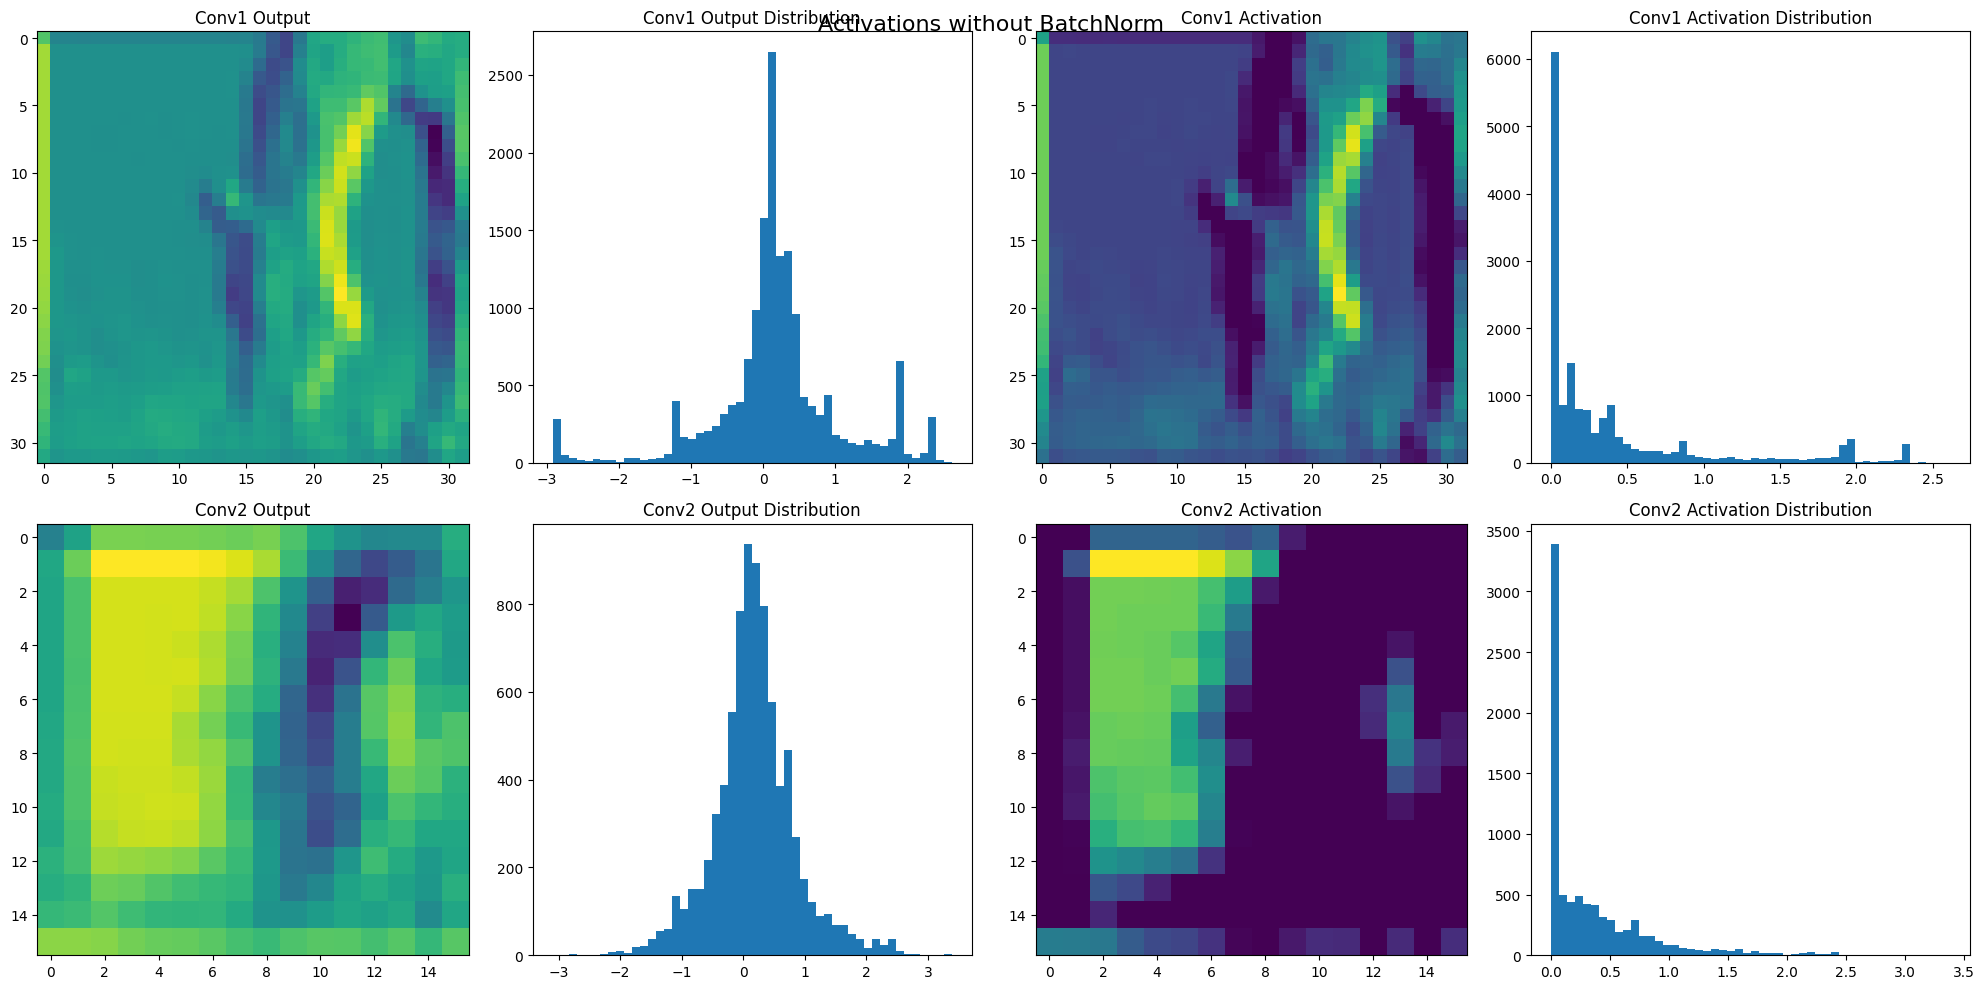

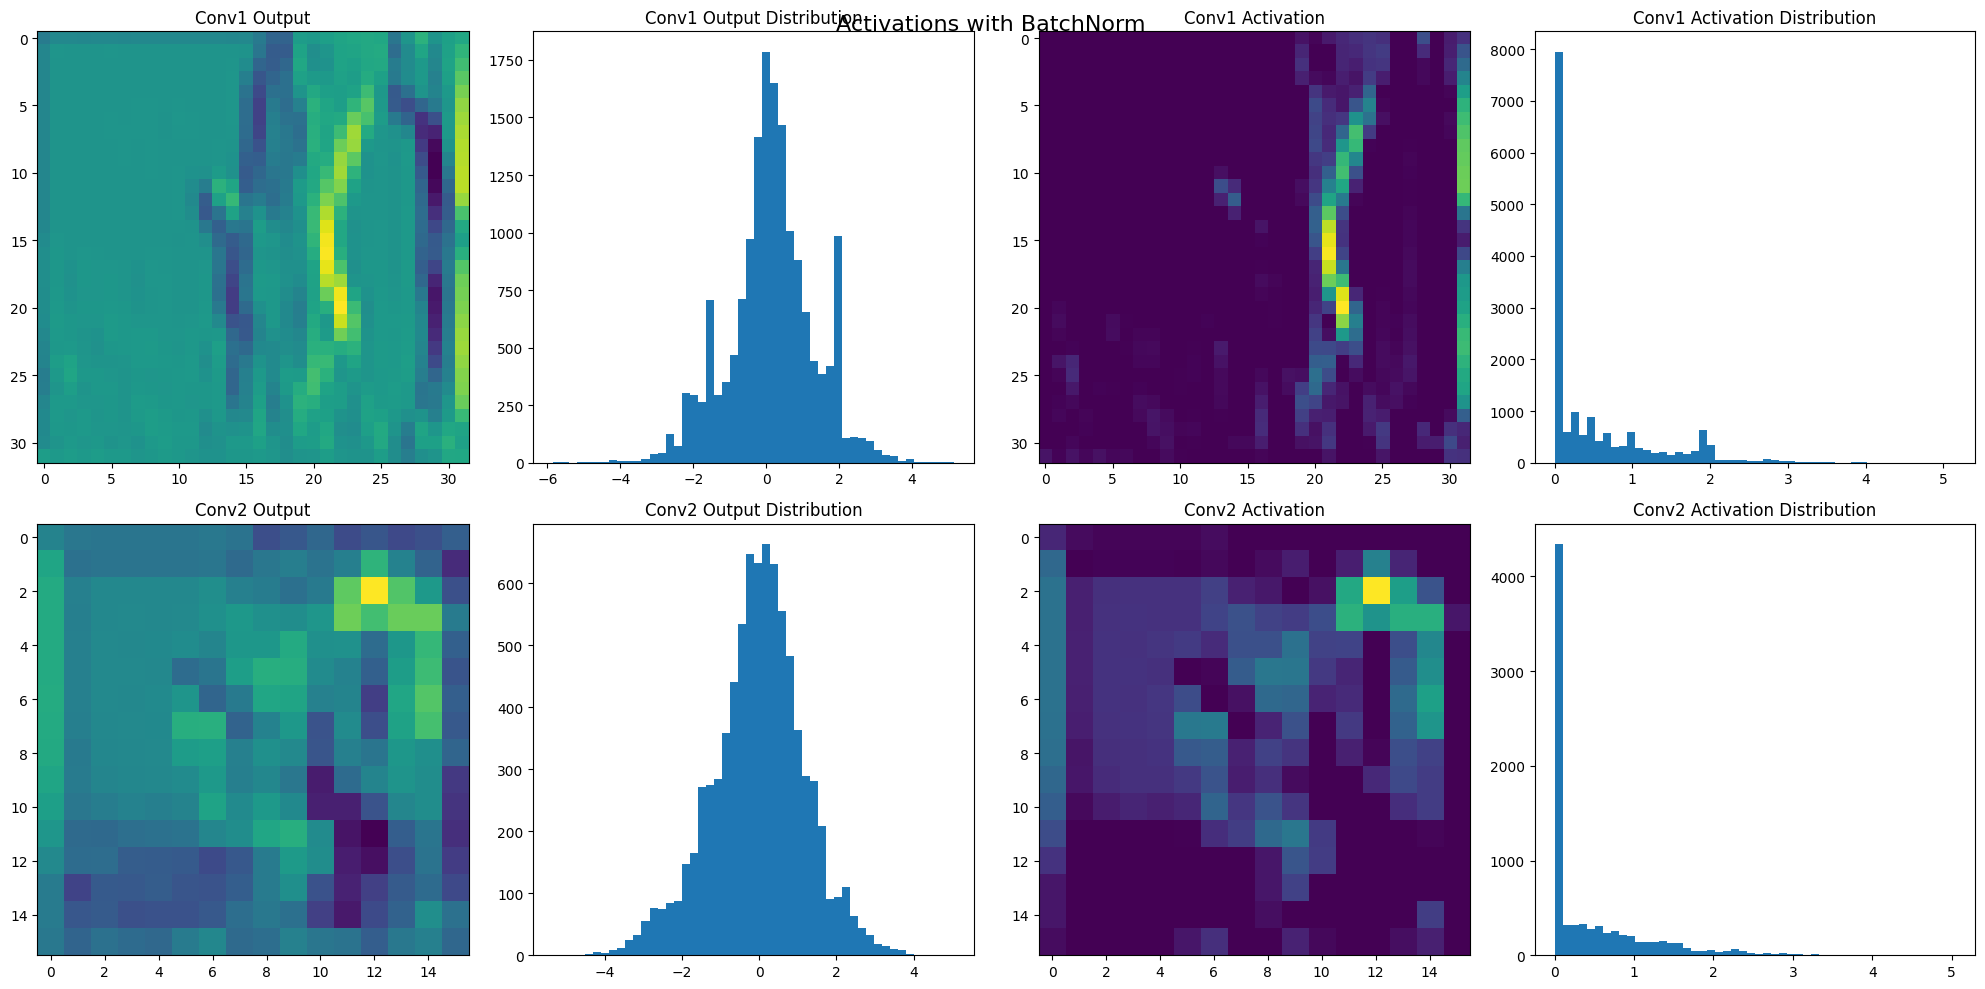

In [ ]:
def get_activation_maps(model, input_image):
    model.eval()
    x = input_image.unsqueeze(0).to(device)

    conv1_out = model.conv1(x)
    if model.use_batchnorm:
        conv1_out = model.bn1(conv1_out)
    conv1_act = nn.functional.relu(conv1_out)
    conv2_out = model.conv2(nn.functional.max_pool2d(conv1_act, 2))
    if model.use_batchnorm:
        conv2_out = model.bn2(conv2_out)
    conv2_act = nn.functional.relu(conv2_out)

    return conv1_out, conv1_act, conv2_out, conv2_act

def plot_activations(conv1_out, conv1_act, conv2_out, conv2_act, use_batchnorm=False):
    fig, axs = plt.subplots(2, 4, figsize=(20, 10))

    axs[0, 0].imshow(conv1_out[0, 0].cpu().detach().numpy())
    axs[0, 0].set_title('Conv1 Output')
    axs[0, 1].hist(conv1_out.cpu().detach().numpy().flatten(), bins=50)
    axs[0, 1].set_title('Conv1 Output Distribution')

    axs[0, 2].imshow(conv1_act[0, 0].cpu().detach().numpy())
    axs[0, 2].set_title('Conv1 Activation')
    axs[0, 3].hist(conv1_act.cpu().detach().numpy().flatten(), bins=50)
    axs[0, 3].set_title('Conv1 Activation Distribution')

    axs[1, 0].imshow(conv2_out[0, 0].cpu().detach().numpy())
    axs[1, 0].set_title('Conv2 Output')
    axs[1, 1].hist(conv2_out.cpu().detach().numpy().flatten(), bins=50)
    axs[1, 1].set_title('Conv2 Output Distribution')

    axs[1, 2].imshow(conv2_act[0, 0].cpu().detach().numpy())
    axs[1, 2].set_title('Conv2 Activation')
    axs[1, 3].hist(conv2_act.cpu().detach().numpy().flatten(), bins=50)
    axs[1, 3].set_title('Conv2 Activation Distribution')

    plt.tight_layout()
    plt.suptitle(f'Activations {"with" if use_batchnorm else "without"} BatchNorm', fontsize=16)
    plt.show()

dataiter = iter(trainloader)
images, _ = next(dataiter)
input_image = images[2]

conv1_out, conv1_act, conv2_out, conv2_act = get_activation_maps(model_without_bn, input_image)
plot_activations(conv1_out, conv1_act, conv2_out, conv2_act, use_batchnorm=False)

conv1_out, conv1_act, conv2_out, conv2_act = get_activation_maps(model_with_bn, input_image)
plot_activations(conv1_out, conv1_act, conv2_out, conv2_act, use_batchnorm=True)

BatchNorm works beacuse it make the network less sensitive to the size of the weights of the previous layer, and since it can hande larger weights the learning rate can be increased too, hence speeding up the training. Also the activation patterns are more pronounced as observable.